# BCG Financial Analysis and Simple Chatbot
**Microsoft, Tesla and Apple — fiscal years 2023–2025**

## Executive summary
I used the updated merged CSV to examine revenue, net income, assets, liabilities and operating cash flow. Microsoft grew across these measures over the period. Apple had the highest revenue in 2025. Tesla's consolidated net income declined substantially. I then connected the same data to a simple chatbot that answers predefined financial questions and returns filing links.

**How to run:** extract the complete ZIP. Keep this notebook and `BCG_Financial_Data_Merged.csv` together in the same folder. Open the notebook from that folder and click **Run All**. No Windows paths or API keys are needed.


## 1. Problem and objectives
The task is to turn financial filing data into understandable comparisons and chatbot answers. I will load and check the CSV, calculate annual growth, make charts, summarize the findings, and build a small question-answering prototype.

The nine company-year records contain 45 required financial figures from original SEC 10-K filings. Values are **USD millions**. Revenue, net income and cash flow cover a year; assets and liabilities are year-end balances. Fiscal year-ends differ between companies. Apple's 2023 had 53 weeks, compared with 52 in 2024 and 2025. Net income is consolidated income, not Tesla's common-stockholder-attributable income.

This notebook performs descriptive analysis, not forecasting or investment advice. The chatbot uses predefined rules; it is not a generative AI model. That keeps the prototype free, simple and reproducible.


## 2. Import the libraries
If needed, install dependencies in a terminal with `python -m pip install pandas matplotlib ipython notebook`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)


## 3. Load the updated CSV
Use the filename exactly as supplied. Do not add `data/` or a Windows path. If the file is missing, the message below identifies the folder Python is checking.


In [2]:
csv_file = Path("BCG_Financial_Data_Merged.csv")

if not csv_file.is_file():
    raise FileNotFoundError(
        f"Put BCG_Financial_Data_Merged.csv in this folder: {Path.cwd()}"
    )

df = pd.read_csv(csv_file)
display(df.head())
print("Rows:", len(df))


,Company,Fiscal Year,Fiscal Year End,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow,Currency,Unit,Source ID,Source URL,Income Statement Reference,Balance Sheet Reference,Cash Flow Reference,Net Income Basis
0,Apple,2023,2023-09-30,383285,96995,352583,290437,110543,USD,millions,AAPL-2023,https://www.sec.gov/Archives/edgar/data/320193...,"Item 8, Consolidated Statements of Operations:...","Item 8, Consolidated Balance Sheets: Total ass...","Item 8, Consolidated Statements of Cash Flows:...","Consolidated net income, before attribution to..."
1,Apple,2024,2024-09-28,391035,93736,364980,308030,118254,USD,millions,AAPL-2024,https://www.sec.gov/Archives/edgar/data/320193...,"Item 8, Consolidated Statements of Operations:...","Item 8, Consolidated Balance Sheets: Total ass...","Item 8, Consolidated Statements of Cash Flows:...","Consolidated net income, before attribution to..."
2,Apple,2025,2025-09-27,416161,112010,359241,285508,111482,USD,millions,AAPL-2025,https://www.sec.gov/Archives/edgar/data/320193...,"Item 8, Consolidated Statements of Operations:...","Item 8, Consolidated Balance Sheets: Total ass...","Item 8, Consolidated Statements of Cash Flows:...","Consolidated net income, before attribution to..."
3,Microsoft,2023,2023-06-30,211915,72361,411976,205753,87582,USD,millions,MSFT-2023,https://www.sec.gov/Archives/edgar/data/789019...,"Item 8, Income Statements: Total revenue; Net ...","Item 8, Balance Sheets: Total assets; Total li...","Item 8, Cash Flows Statements: Net cash from o...","Consolidated net income, before attribution to..."
4,Microsoft,2024,2024-06-30,245122,88136,512163,243686,118548,USD,millions,MSFT-2024,https://www.sec.gov/Archives/edgar/data/789019...,"Item 8, Income Statements: Total revenue; Net ...","Item 8, Balance Sheets: Total assets; Total li...","Item 8, Cash Flows Statements: Net cash from o...","Consolidated net income, before attribution to..."


Rows: 9


## 4. Clean and validate the data
I keep the source references, convert the financial columns to numbers and sort by company/year before calculating growth. Missing or duplicate records trigger an error rather than silently changing the data.


In [3]:
metrics = ["Total Revenue", "Net Income", "Total Assets",
           "Total Liabilities", "Operating Cash Flow"]
companies = ["Apple", "Microsoft", "Tesla"]
years = [2023, 2024, 2025]

for column in metrics + ["Fiscal Year"]:
    df[column] = pd.to_numeric(df[column], errors="raise")

df["Fiscal Year End"] = pd.to_datetime(df["Fiscal Year End"], errors="raise")
df = df.sort_values(["Company", "Fiscal Year"]).reset_index(drop=True)

assert len(df) == 9, "Expected nine records."
assert not df.duplicated(["Company", "Fiscal Year"]).any(), "Duplicate records."
assert not df.isna().any().any(), "Missing values found."
assert set(zip(df["Company"], df["Fiscal Year"])) == {(c, y) for c in companies for y in years}
assert df["Currency"].eq("USD").all() and df["Unit"].eq("millions").all()
assert not df[metrics].isin([float("inf"), -float("inf")]).any().any()

display(df[["Company", "Fiscal Year", *metrics]])
print("Validation passed: nine records, complete coverage and consistent units.")


,Company,Fiscal Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow
0,Apple,2023,383285,96995,352583,290437,110543
1,Apple,2024,391035,93736,364980,308030,118254
2,Apple,2025,416161,112010,359241,285508,111482
3,Microsoft,2023,211915,72361,411976,205753,87582
4,Microsoft,2024,245122,88136,512163,243686,118548
5,Microsoft,2025,281724,101832,619003,275524,136162
6,Tesla,2023,96773,14974,106618,43009,13256
7,Tesla,2024,97690,7153,122070,48390,14923
8,Tesla,2025,94827,3855,137806,54941,14747


Validation passed: nine records, complete coverage and consistent units.


## 5. Calculate year-over-year changes
**Growth (%) = (current value / previous value − 1) × 100.** I calculate growth separately for each company. The 2023 results remain blank because 2022 is outside the dataset. A zero previous value also gives an unavailable result.


In [4]:
growth_columns = []

for metric in metrics:
    previous = df.groupby("Company")[metric].shift(1)
    growth_name = metric + " Growth (%)"
    df[growth_name] = df.groupby("Company")[metric].pct_change(fill_method=None) * 100
    df.loc[previous.eq(0), growth_name] = float("nan")
    growth_columns.append(growth_name)

display(df[["Company", "Fiscal Year", *growth_columns]].round(2))


,Company,Fiscal Year,Total Revenue Growth (%),Net Income Growth (%),Total Assets Growth (%),Total Liabilities Growth (%),Operating Cash Flow Growth (%)
0,Apple,2023,NaN,NaN,NaN,NaN,NaN
1,Apple,2024,2.02,-3.36,3.52,6.06,6.98
2,Apple,2025,6.43,19.50,-1.57,-7.31,-5.73
3,Microsoft,2023,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2024,15.67,21.80,24.32,18.44,35.36
5,Microsoft,2025,14.93,15.54,20.86,13.07,14.86
6,Tesla,2023,NaN,NaN,NaN,NaN,NaN
7,Tesla,2024,0.95,-52.23,14.49,12.51,12.58
8,Tesla,2025,-2.93,-46.11,12.89,13.54,-1.18


## 6. Calculate useful financial ratios
Net profit margin measures earnings relative to revenue. Operating cash flow margin measures operating cash generation relative to revenue. Liabilities-to-assets includes all liabilities; it is not a debt-only ratio. I do not sum assets or liabilities across years.


In [5]:
df["Net Profit Margin (%)"] = df["Net Income"] / df["Total Revenue"].replace(0, float("nan")) * 100
df["Operating Cash Flow Margin (%)"] = df["Operating Cash Flow"] / df["Total Revenue"].replace(0, float("nan")) * 100
df["Liabilities to Assets (%)"] = df["Total Liabilities"] / df["Total Assets"].replace(0, float("nan")) * 100

display(df[["Company", "Fiscal Year", "Net Profit Margin (%)",
            "Operating Cash Flow Margin (%)", "Liabilities to Assets (%)"]].round(2))


,Company,Fiscal Year,Net Profit Margin (%),Operating Cash Flow Margin (%),Liabilities to Assets (%)
0,Apple,2023,25.31,28.84,82.37
1,Apple,2024,23.97,30.24,84.40
2,Apple,2025,26.92,26.79,79.48
3,Microsoft,2023,34.15,41.33,49.94
4,Microsoft,2024,35.96,48.36,47.58
5,Microsoft,2025,36.15,48.33,44.51
6,Tesla,2023,15.47,13.70,40.34
7,Tesla,2024,7.32,15.28,39.64
8,Tesla,2025,4.07,15.55,39.87


## 7. Plot all five financial metrics
The charts show financial scale and how each measure changed over the three fiscal years. Company reporting periods differ, so these are fiscal-year comparisons rather than identical calendar windows.


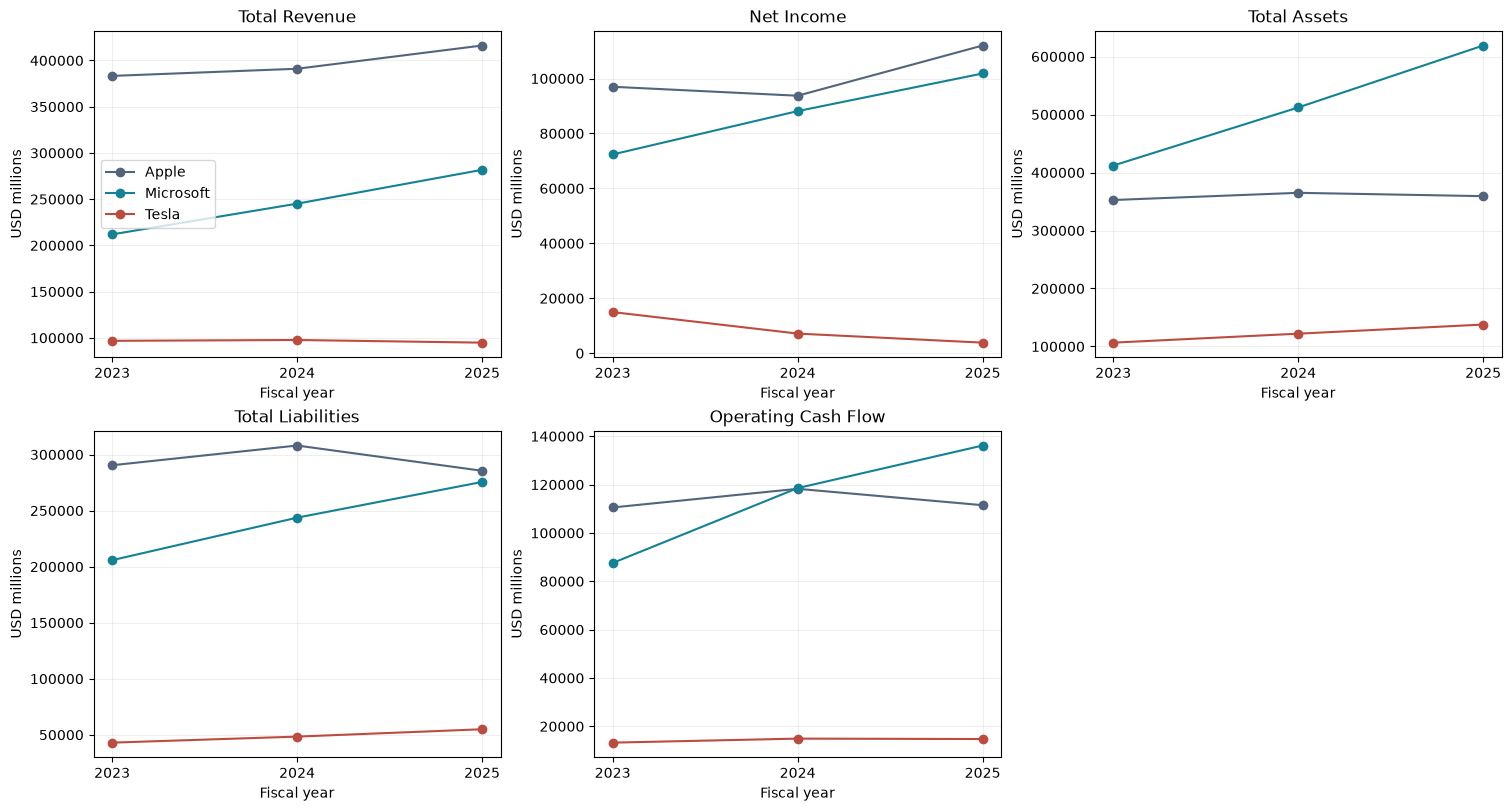

In [6]:
colors = {"Apple": "#52657D", "Microsoft": "#148296", "Tesla": "#BC4B40"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

for ax, metric in zip(axes.flat, metrics):
    for company in companies:
        company_data = df[df["Company"] == company]
        ax.plot(company_data["Fiscal Year"], company_data[metric],
                marker="o", label=company, color=colors[company])
    ax.set_title(metric)
    ax.set_xlabel("Fiscal year")
    ax.set_ylabel("USD millions")
    ax.set_xticks(years)
    ax.grid(alpha=0.2)

axes.flat[-1].axis("off")
axes.flat[0].legend()
plt.show()


## 8. Summarize the findings
This summary uses the calculated DataFrame. Numbers are rounded only for display.


In [7]:
latest = df[df["Fiscal Year"] == 2025].copy()

for _, row in latest.iterrows():
    print(f"{row['Company']} — FY2025")
    print(f"  Revenue: USD {row['Total Revenue']:,.0f} million")
    print(f"  Revenue growth: {row['Total Revenue Growth (%)']:.2f}%")
    print(f"  Net income growth: {row['Net Income Growth (%)']:.2f}%")
    print(f"  Operating cash flow growth: {row['Operating Cash Flow Growth (%)']:.2f}%")
    print(f"  Net profit margin: {row['Net Profit Margin (%)']:.2f}%")
    print()

print("Highest 2025 revenue:", latest.loc[latest["Total Revenue"].idxmax(), "Company"])
print("Highest 2025 net profit margin:", latest.loc[latest["Net Profit Margin (%)"].idxmax(), "Company"])


Apple — FY2025
  Revenue: USD 416,161 million
  Revenue growth: 6.43%
  Net income growth: 19.50%
  Operating cash flow growth: -5.73%
  Net profit margin: 26.92%

Microsoft — FY2025
  Revenue: USD 281,724 million
  Revenue growth: 14.93%
  Net income growth: 15.54%
  Operating cash flow growth: 14.86%
  Net profit margin: 36.15%

Tesla — FY2025
  Revenue: USD 94,827 million
  Revenue growth: -2.93%
  Net income growth: -46.11%
  Operating cash flow growth: -1.18%
  Net profit margin: 4.07%

Highest 2025 revenue: Apple
Highest 2025 net profit margin: Microsoft


**Interpretation:** Microsoft shows broad growth across the selected measures. Apple leads revenue scale, but its 2025 operating cash flow declined from 2024 while net income rose. Tesla's consolidated net income fell from USD 14,974 million in 2023 to USD 3,855 million in 2025, while its assets increased.

**Practical next step:** investigate tax effects, working capital, pricing and segment performance using filing notes before claiming why these changes occurred. These five metrics identify questions to investigate; they do not establish causes or business quality rankings.


## 9. Build a simple financial chatbot
To keep the code easy to understand, pass the company and year separately. Use one of the questions in the dictionary below. For example: `chatbot("Microsoft", 2025, "revenue")`.

The chatbot retrieves numbers from the same DataFrame and includes SEC links. It handles unavailable companies, years, questions and growth values. It answers predefined questions, not unrestricted natural language.


In [8]:
questions = {
    "revenue": "Total Revenue",
    "net income": "Net Income",
    "assets": "Total Assets",
    "liabilities": "Total Liabilities",
    "operating cash flow": "Operating Cash Flow",
    "revenue growth": "Total Revenue Growth (%)",
    "net income growth": "Net Income Growth (%)",
    "assets growth": "Total Assets Growth (%)",
    "liabilities growth": "Total Liabilities Growth (%)",
    "operating cash flow growth": "Operating Cash Flow Growth (%)",
    "profit margin": "Net Profit Margin (%)",
}

def chatbot(company, year, question):
    company = str(company).strip().title()
    question = str(question).strip().lower()

    if company not in companies:
        return "Choose Apple, Microsoft or Tesla."
    if str(year) not in ["2023", "2024", "2025"]:
        return "Choose 2023, 2024 or 2025."
    if question not in questions:
        return "Supported questions: " + ", ".join(questions)

    year = int(year)
    row = df[(df["Company"] == company) & (df["Fiscal Year"] == year)].iloc[0]
    column = questions[question]
    value = row[column]

    if pd.isna(value):
        return "Growth is unavailable because the prior year is missing or its value is zero."

    unit = "%" if column.endswith("(%)") else " million USD"
    answer = f"{company} {question} in FY{year}: {value:,.2f}{unit}."
    answer += f" Fiscal year ended {row['Fiscal Year End'].date()}."
    answer += " Source: " + row["Source URL"]

    if question.endswith("growth"):
        prior = df[(df["Company"] == company) & (df["Fiscal Year"] == year - 1)].iloc[0]
        answer += " Prior-year source: " + prior["Source URL"]

    return answer

print("Available questions:", ", ".join(questions))


Available questions: revenue, net income, assets, liabilities, operating cash flow, revenue growth, net income growth, assets growth, liabilities growth, operating cash flow growth, profit margin


## 10. Try and test the chatbot
Change the company, year and question below, then rerun the cell. I use ordinary function calls instead of an input loop, so Run All completes without waiting for keyboard input.


In [9]:
print(chatbot("Microsoft", 2025, "revenue"))
print()
print(chatbot("Tesla", 2025, "net income growth"))
print()
print(chatbot("Apple", 2025, "profit margin"))


Microsoft revenue in FY2025: 281,724.00 million USD. Fiscal year ended 2025-06-30. Source: https://www.sec.gov/Archives/edgar/data/789019/000095017025100235/msft-20250630.htm

Tesla net income growth in FY2025: -46.11%. Fiscal year ended 2025-12-31. Source: https://www.sec.gov/Archives/edgar/data/1318605/000162828026003952/tsla-20251231.htm Prior-year source: https://www.sec.gov/Archives/edgar/data/1318605/000162828025003063/tsla-20241231.htm

Apple profit margin in FY2025: 26.92%. Fiscal year ended 2025-09-27. Source: https://www.sec.gov/Archives/edgar/data/320193/000032019325000079/aapl-20250927.htm


In [10]:
tests = {
    "Correct revenue": "281,724.00" in chatbot("Microsoft", 2025, "revenue"),
    "Correct consolidated net income": "3,855.00" in chatbot("Tesla", 2025, "net income"),
    "Correct cash flow": "118,254.00" in chatbot("Apple", 2024, "operating cash flow"),
    "Correct calculated growth": f"{(281724 / 245122 - 1) * 100:.2f}%" in chatbot("Microsoft", 2025, "revenue growth"),
    "Source included": "https://www.sec.gov/" in chatbot("Apple", 2025, "assets"),
    "Prior source included for growth": "Prior-year source:" in chatbot("Tesla", 2025, "net income growth"),
    "Missing prior year handled": "unavailable" in chatbot("Tesla", 2023, "revenue growth"),
    "Unknown company handled": chatbot("Amazon", 2025, "revenue").startswith("Choose Apple"),
    "Unknown year handled": chatbot("Apple", 2026, "revenue").startswith("Choose 2023"),
    "Unknown question handled": chatbot("Apple", 2025, "stock price").startswith("Supported questions"),
}
test_table = pd.DataFrame(tests.items(), columns=["Test", "Passed"])
display(test_table)
assert all(tests.values()), "A chatbot test failed."
assert df.loc[df["Fiscal Year"] == 2023, growth_columns].isna().all().all()
print(f"All {len(tests)} chatbot tests passed.")


,Test,Passed
0,Correct revenue,True
1,Correct consolidated net income,True
2,Correct cash flow,True
3,Correct calculated growth,True
4,Source included,True
5,Prior source included for growth,True
6,Missing prior year handled,True
7,Unknown company handled,True
8,Unknown year handled,True
9,Unknown question handled,True


All 10 chatbot tests passed.


## 11. Save the analysis
The updated merged source CSV stays unchanged. The new analysis file contains the financial values, sources, growth columns and ratios. The 2023 growth values remain blank rather than becoming zero.


In [11]:
df.to_csv("BCG_Financial_Analysis_Results.csv", index=False)
test_table.to_csv("BCG_Chatbot_Test_Results.csv", index=False)
print("Saved BCG_Financial_Analysis_Results.csv and BCG_Chatbot_Test_Results.csv")


Saved BCG_Financial_Analysis_Results.csv and BCG_Chatbot_Test_Results.csv


## 12. Final report
I completed the data-loading, validation, annual growth analysis, ratio calculations, charts, observations, simple chatbot and tests using one shared updated CSV.

**Limits:** only three years per company, different fiscal calendars, consolidated earnings definitions and a chatbot limited to predefined questions. No predictive model or live GenAI service is included. Before deployment, I would add more periods, richer question handling and further testing. A generative explanation layer would require its own model integration and evaluation.

**Submission:** use this executed notebook or the included HTML report for the analysis task. The chatbot code and tests provide a simple Task 2 prototype. Follow any additional requirements shown by the simulation portal.
